# Klasifikasi Penggunaan dan Tutupan Lahan (Land Use / Land Cover)
### Citra Sentinel-2A + Algoritma Naive Bayes & K-Nearest Neighbors (KNN)

**Mata Kuliah:** Penambangan Data Sains (*Data Mining*)

---

## 1. Business Understanding (Pemahaman Bisnis)

**Latar Belakang**
Pemetaan tutupan lahan (*Land Cover*) sangat krusial untuk berbagai kepentingan analisis ruang, pengelolaan lingkungan, hingga perencanaan kota. Proses klasifikasi citra satelit multispektral (seperti Sentinel-2A) secara manual memakan waktu yang sangat lama. Oleh karena itu, kita memanfaatkan *Machine Learning* untuk mendeteksi secara otomatis.

**Tujuan**
1. Membangun model machine learning untuk mengklasifikasikan wilayah menjadi beberapa kelas (seperti Sawah, Bangunan, Mangrove, Hutan, Laut, dan Danau).
2. Membandingkan performa antara metode **Naive Bayes** dan **K-Nearest Neighbors (KNN)**.
3. Memvisualisasikan keseluruhan hasil klasifikasi/digitasi yang terpetakan ke dalam *interactive map* (Folium).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import geopandas as gpd
import warnings
warnings.filterwarnings('ignore')

# Machine Learning Modules
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


---
## 2. Data Understanding (Pengumpulan & Pemahaman Data)
Kita akan memuat dataset citra satelit hasil ekstraksi (berisi nilai band spektral asli dan indeks turunan seperti NDVI, NDWI, dll).


### Data Collection

In [ ]:
"""
Sentinel-2 L2A (CDSE openEO) per-tile + ekstraksi KELAS PER PIKSEL -> CSV.

Setiap baris CSV = satu piksel, dengan penanda poligon asalnya:
  - poligon_id : ID stabil poligon, mis. "Sawah_0012" (nama kelas + nomor fitur di file sumbernya)
  - poligon_no : nomor fitur (urutan baris) di shapefile sumber, mulai dari 0
  - sampel_id  : indeks poligon pada GeoDataFrame gabungan (internal)

Poligon sampel masuk ke SEMUA tile yang dilewatinya. Piksel di zona overlap antar-tile
hanya diambil sekali (dimiliki sel grid-nya).

Pakai (script):   python sentinel2_piksel.py
Pakai (notebook): from sentinel2_piksel import main; main()
"""

import threading
import time
from datetime import datetime
from pathlib import Path

import geopandas as gpd
import numpy as np
import openeo
import pandas as pd
import rasterio
from openeo.extra.job_management import CsvJobDatabase, MultiBackendJobManager
from rasterio.features import rasterize
from rasterio.mask import mask as rio_mask
from rasterio.warp import transform as warp_transform
from rasterio.windows import Window
from shapely.geometry import box
from shapely.validation import make_valid

# ==============================================================================
# KONFIGURASI
# ==============================================================================
SUMBER = {  # nama kelas: (file, kode label)
    "Sawah": ("/content/drive/MyDrive/PSD/sawah.zip", 1),
    "Bangunan": ("/content/drive/MyDrive/PSD/bangunan.zip", 2),
    "Hutan": ("/content/drive/MyDrive/PSD/Hutan.zip", 3),
    "Danau": ("/content/drive/MyDrive/PSD/Danau.zip", 4),
    "Laut": ("/content/drive/MyDrive/PSD/laut2.zip", 5),
    "Mangrove": ("/content/drive/MyDrive/PSD/Mangrove.zip", 6),
}

TILE_DEG = 0.20      # ukuran tile ~22 km (~2200 x 2200 piksel @10 m)
BUFFER_DEG = 0.005   # margin ~500 m di sekeliling sampel

TANGGAL = ["2026-09-01", "2026-09-30"]
BANDS = ["B02", "B03", "B04", "B08", "B11"]  # Blue, Green, Red, NIR, SWIR
PAKAI_MASK_SCL = True  # mask awan/bayangan per piksel pakai band SCL
MAX_CLOUD = 30         # filter awan level scene (kalau PAKAI_MASK_SCL=False, pakai ~10)

PARALEL = 2            # job bersamaan (akun gratis CDSE biasanya max 2)

# Ekstraksi piksel
MAKS_PIKSEL_PER_POLIGON = 2000  # None = ambil SEMUA piksel (hati-hati: poligon laut/hutan bisa jutaan -> CSV sangat besar)
SEED = 42
BUAT_RASTER_LABEL = True        # buat label_<tile>.tif di samping citra tiap tile

OUT_DIR = Path("hasil_s2_piksel")
JOB_DB_PATH = OUT_DIR / "daftar_job.csv"
PETA_CSV = OUT_DIR / "peta_sampel_tile.csv"
PIKSEL_OUT = OUT_DIR / "dataset.csv"


# ==============================================================================
# 1. BACA & GABUNGKAN SAMPEL
# ==============================================================================
def baca_semua() -> gpd.GeoDataFrame:
    bagian = []
    for nama, (file, label) in SUMBER.items():
        g = gpd.read_file(file).to_crs("EPSG:4326")
        # nomor fitur asli di file sumber (dicatat SEBELUM filter agar tetap stabil)
        g["poligon_no"] = np.arange(len(g))
        g = g[g.geometry.notna() & ~g.geometry.is_empty].copy()
        g["geometry"] = g.geometry.apply(lambda x: x if x.is_valid else make_valid(x))
        g["label_teks"] = nama
        g["label"] = label
        g["poligon_id"] = [f"{nama}_{n:04d}" for n in g["poligon_no"]]
        g = g[["poligon_id", "poligon_no", "label", "label_teks", "geometry"]]
        print(f"Jumlah sampel {nama:<9}: {len(g)}  bounds={[round(v, 3) for v in g.total_bounds]}")
        bagian.append(g)

    gdf = gpd.GeoDataFrame(pd.concat(bagian, ignore_index=True), crs="EPSG:4326")
    print(f"Total sampel gabungan   : {len(gdf)}")
    return gdf


# ==============================================================================
# 2. BAGI JADI TILE (poligon masuk ke semua sel yang dilewatinya)
# ==============================================================================
def buat_tile(gdf: gpd.GeoDataFrame):
    T, B = TILE_DEG, BUFFER_DEG
    peta, batas, sel_xy = [], {}, {}

    for idx, geom in gdf.geometry.items():
        minx, miny, maxx, maxy = geom.bounds
        for gx in range(int(np.floor(minx / T)), int(np.floor(maxx / T)) + 1):
            for gy in range(int(np.floor(miny / T)), int(np.floor(maxy / T)) + 1):
                sel = box(gx * T, gy * T, (gx + 1) * T, (gy + 1) * T)
                if not geom.intersects(sel):
                    continue
                bagian = geom.intersection(sel)
                if bagian.is_empty:
                    continue
                b = bagian.bounds
                tid = f"x{gx}_y{gy}"
                peta.append({"tile_id": tid, "sampel_id": idx, "poligon_id": gdf.at[idx, "poligon_id"]})
                sel_xy[tid] = (gx, gy)
                if tid in batas:
                    o = batas[tid]
                    batas[tid] = (min(o[0], b[0]), min(o[1], b[1]), max(o[2], b[2]), max(o[3], b[3]))
                else:
                    batas[tid] = b

    tiles = pd.DataFrame(
        [
            {
                "tile_id": tid,
                "gx": sel_xy[tid][0],
                "gy": sel_xy[tid][1],
                "west": b[0] - B,
                "south": b[1] - B,
                "east": b[2] + B,
                "north": b[3] + B,
            }
            for tid, b in batas.items()
        ]
    )
    peta = pd.DataFrame(peta)
    tiles["n_sampel"] = tiles["tile_id"].map(peta.groupby("tile_id")["sampel_id"].nunique())

    lebar_km = (tiles.east - tiles.west) * 111.32 * np.cos(np.radians((tiles.north + tiles.south) / 2))
    tinggi_km = (tiles.north - tiles.south) * 110.57
    print(f"\nJumlah tile (job)       : {len(tiles)}")
    print(f"Ukuran tile terbesar    : {lebar_km.max():.1f} km x {tinggi_km.max():.1f} km")
    print(f"Total area diunduh      : {(lebar_km * tinggi_km).sum():,.0f} km2")
    return tiles, peta


# ==============================================================================
# 3. JALANKAN BATCH JOB PER TILE
# ==============================================================================
def _jam() -> str:
    return datetime.now().strftime("%H:%M:%S")


def start_job(row, connection, **kwargs):
    print(f"[{_jam()}] >> Mengirim job tile {row['tile_id']} ({row.get('n_sampel', '?')} poligon)...", flush=True)
    bbox = {
        "west": float(row["west"]),
        "south": float(row["south"]),
        "east": float(row["east"]),
        "north": float(row["north"]),
    }
    bands = BANDS + ["SCL"] if PAKAI_MASK_SCL else BANDS
    cube = connection.load_collection(
        "SENTINEL2_L2A",
        spatial_extent=bbox,
        temporal_extent=TANGGAL,
        bands=bands,
        max_cloud_cover=MAX_CLOUD,
    )

    if PAKAI_MASK_SCL:
        scl = cube.band("SCL")
        # 1=jenuh, 3=bayangan awan, 8/9=awan sedang/tinggi, 10=cirrus
        mask_awan = (scl == 1) | (scl == 3) | (scl == 8) | (scl == 9) | (scl == 10)
        cube = cube.filter_bands(BANDS).mask(mask_awan)

    komposit = cube.median_time()
    return komposit.create_job(title=f"s2_{row['tile_id']}", out_format="GTiff")


INTERVAL_LAPOR = 30  # detik antar laporan progres di terminal


class ManagerBerlapor(MultiBackendJobManager):
    """Manager job yang mencetak pesan saat job selesai / gagal."""

    def on_job_done(self, job, row):
        print(f"[{_jam()}] [OK]    Tile {row['tile_id']} selesai (job {job.job_id}), mengunduh hasil...", flush=True)
        super().on_job_done(job, row)
        print(f"[{_jam()}] [OK]    Tile {row['tile_id']} terunduh.", flush=True)

    def on_job_error(self, job, row):
        print(f"[{_jam()}] [ERROR] Tile {row['tile_id']} gagal (job {job.job_id}). Log disimpan di folder job.", flush=True)
        super().on_job_error(job, row)


def _lapor_berkala(job_db, berhenti: threading.Event):
    mulai = time.time()
    while not berhenti.wait(INTERVAL_LAPOR):
        try:
            df = job_db.read()
        except Exception:  # file sedang ditulis manager; lewati satu siklus
            continue
        n = len(df)
        hitung = df["status"].value_counts().to_dict()
        selesai = hitung.get("finished", 0)
        gagal = sum(hitung.get(s, 0) for s in ("error", "start_failed", "skipped"))
        jalan = hitung.get("running", 0) + hitung.get("queued", 0) + hitung.get("created", 0)
        belum = hitung.get("not_started", 0)
        persen = 100 * selesai / n if n else 0
        menit = (time.time() - mulai) / 60
        print(
            f"[{_jam()}] Progres job: {selesai}/{n} selesai ({persen:.0f}%) | "
            f"berjalan/antre {jalan} | belum mulai {belum} | gagal {gagal} | {menit:.1f} menit",
            flush=True,
        )


def jalankan_job(tiles: pd.DataFrame, ulangi_error: bool = True):
    OUT_DIR.mkdir(exist_ok=True)

    conn = openeo.connect("openeo.dataspace.copernicus.eu")
    conn.authenticate_oidc()

    manager = ManagerBerlapor(root_dir=OUT_DIR, poll_sleep=30)
    manager.add_backend("cdse", connection=conn, parallel_jobs=PARALEL)

    job_db = CsvJobDatabase(JOB_DB_PATH)
    if not job_db.exists():
        job_db.initialize_from_df(tiles)
    elif ulangi_error:
        df = job_db.read()
        gagal = df["status"].isin(["error", "start_failed", "skipped"])
        if gagal.any():
            print(f"Mengulang {int(gagal.sum())} job yang sebelumnya gagal.")
            df.loc[gagal, "status"] = "not_started"
            job_db.persist(df)

    # thread pemantau: cetak ringkasan status job tiap INTERVAL_LAPOR detik
    berhenti = threading.Event()
    pemantau = threading.Thread(target=_lapor_berkala, args=(job_db, berhenti), daemon=True)
    pemantau.start()
    try:
        manager.run_jobs(start_job=start_job, job_db=job_db)
    finally:
        berhenti.set()
        pemantau.join(timeout=5)

    df = job_db.read()
    print("\nRingkasan status job:")
    print(df["status"].value_counts().to_string())
    return df


# ==============================================================================
# 4. EKSTRAK KELAS PER PIKSEL -> CSV
# ==============================================================================
def _nama_band(src) -> list:
    desc = list(src.descriptions or [])
    if len(desc) == src.count and all(desc) and set(BANDS) <= set(desc):
        return desc
    return BANDS  # asumsi urutan band sama dengan permintaan


def _valid_mask(data, nodata, masked=None):
    """data: (band, H, W). Piksel valid = semua band terbatas, > 0, bukan nodata."""
    ok = np.isfinite(data).all(axis=0) & (data > 0).all(axis=0)
    if nodata is not None and not np.isnan(nodata):
        ok &= ~(data == nodata).any(axis=0)
    if masked is not None:
        ok &= ~masked
    return ok


def _piksel_geom(src, geom):
    """Semua piksel valid yang pusatnya di dalam geometri.
    Return (nilai[band, n], baris_raster, kolom_raster, x, y) dalam CRS raster, atau None."""
    nodata = src.nodata

    if geom.geom_type == "Point":
        rr, cc = src.index(geom.x, geom.y)
        if not (0 <= rr < src.height and 0 <= cc < src.width):
            return None
        data = src.read(window=Window(cc, rr, 1, 1)).astype("float64")  # (band,1,1)
        ok = _valid_mask(data, nodata)
        row0, col0 = rr, cc
    else:
        ok = None
        for all_touched in (False, True):  # poligon sangat kecil: coba lagi dengan all_touched
            try:
                arr, tr = rio_mask(src, [geom], crop=True, all_touched=all_touched, filled=False)
            except ValueError:  # tidak beririsan dengan raster
                return None
            data = np.ma.getdata(arr).astype("float64")
            ok = _valid_mask(data, nodata, np.ma.getmaskarray(arr).any(axis=0))
            row0 = int(round((tr.f - src.transform.f) / src.transform.e))
            col0 = int(round((tr.c - src.transform.c) / src.transform.a))
            if ok.any():
                break
        if ok is None or not ok.any():
            return None

    r_idx, c_idx = np.nonzero(ok)
    if len(r_idx) == 0:
        return None
    nilai = data[:, r_idx, c_idx]
    px_row, px_col = row0 + r_idx, col0 + c_idx
    xs, ys = rasterio.transform.xy(src.transform, px_row, px_col)
    return nilai, px_row, px_col, np.asarray(xs), np.asarray(ys)


def tambah_indeks(df: pd.DataFrame) -> pd.DataFrame:
    e = 1e-9
    df["NDVI"] = (df["B08"] - df["B04"]) / (df["B08"] + df["B04"] + e)
    df["NDWI"] = (df["B03"] - df["B08"]) / (df["B03"] + df["B08"] + e)
    df["MNDWI"] = (df["B03"] - df["B11"]) / (df["B03"] + df["B11"] + e)
    df["NDBI"] = (df["B11"] - df["B08"]) / (df["B11"] + df["B08"] + e)
    return df


def _tif_tile(r):
    tifs = sorted(p for p in OUT_DIR.glob(f"job_{r['id']}/*.tif") if not p.name.startswith("label_"))
    return tifs[0] if tifs else None


def ekstrak_piksel(gdf, db, peta) -> pd.DataFrame:
    rng = np.random.default_rng(SEED)
    T = TILE_DEG
    potongan = []
    selesai = db[db["status"] == "finished"]
    print(f"\nEkstraksi piksel dari {len(selesai)} tile yang selesai...")

    total_tile = len(selesai)
    total_piksel = 0
    t0 = time.time()

    for no_tile, (_, r) in enumerate(selesai.iterrows(), start=1):
        tif = _tif_tile(r)
        if tif is None:
            print(f"  [!] File .tif tidak ditemukan untuk tile {r['tile_id']} (job {r['id']})")
            continue

        cx0, cy0 = int(r["gx"]) * T, int(r["gy"]) * T
        ids = peta.loc[peta["tile_id"] == r["tile_id"], "sampel_id"].unique()
        n_poli = len(ids)
        piksel_tile = 0
        print(f"[{_jam()}] Tile {no_tile}/{total_tile} ({r['tile_id']}): {n_poli} poligon", flush=True)

        with rasterio.open(tif) as src:
            nama_band = _nama_band(src)
            sub_r = gdf.loc[ids].to_crs(src.crs)

            for no_poli, (idx, row) in enumerate(sub_r.iterrows(), start=1):
                if no_poli % 25 == 0 or no_poli == n_poli:
                    print(
                        f"    poligon {no_poli}/{n_poli} | piksel tile ini: {piksel_tile:,} | "
                        f"total: {total_piksel:,} | {(time.time() - t0) / 60:.1f} menit",
                        end="\r", flush=True,
                    )
                hasil = _piksel_geom(src, row.geometry)
                if hasil is None:
                    continue
                nilai, px_row, px_col, xs, ys = hasil

                lon, lat = warp_transform(src.crs, "EPSG:4326", xs.tolist(), ys.tolist())
                lon, lat = np.asarray(lon), np.asarray(lat)

                # hanya piksel yang pusatnya di dalam sel grid tile ini -> tidak ada duplikat antar-tile
                pilih = np.flatnonzero((lon >= cx0) & (lon < cx0 + T) & (lat >= cy0) & (lat < cy0 + T))
                if len(pilih) == 0:
                    continue
                if MAKS_PIKSEL_PER_POLIGON and len(pilih) > MAKS_PIKSEL_PER_POLIGON:
                    pilih = rng.choice(pilih, MAKS_PIKSEL_PER_POLIGON, replace=False)

                d = {
                    "poligon_id": row["poligon_id"],   # penanda poligon asal
                    "poligon_no": row["poligon_no"],
                    "sampel_id": idx,
                    "tile_id": r["tile_id"],
                    "label": row["label"],
                    "label_teks": row["label_teks"],
                    "px_row": px_row[pilih],
                    "px_col": px_col[pilih],
                    "lon": lon[pilih],
                    "lat": lat[pilih],
                }
                for i, nb in enumerate(nama_band):
                    d[nb] = nilai[i, pilih]
                potongan.append(pd.DataFrame(d))
                piksel_tile += len(pilih)
                total_piksel += len(pilih)

        print(f"\n    -> tile {r['tile_id']} selesai: {piksel_tile:,} piksel", flush=True)

    if not potongan:
        print("Tidak ada piksel yang berhasil diekstrak.")
        return pd.DataFrame()

    df = pd.concat(potongan, ignore_index=True)

    # piksel yang sama dimiliki poligon kelas berbeda = label ambigu -> dibuang
    kunci = ["tile_id", "px_row", "px_col"]
    ganda = df.duplicated(kunci, keep=False)
    konflik = ganda & (df.groupby(kunci)["label"].transform("nunique") > 1)
    if konflik.any():
        print(f"Membuang {int(konflik.sum())} piksel dengan label bertabrakan antar-kelas.")
    df = df[~konflik]

    # piksel yang sama dimiliki >1 poligon dari kelas yang sama: simpan satu baris saja
    # (poligon_id = poligon yang pertama memprosesnya)
    n_sebelum = len(df)
    df = df.drop_duplicates(kunci).reset_index(drop=True)
    if n_sebelum != len(df):
        print(f"Menghapus {n_sebelum - len(df)} piksel ganda (poligon sekelas yang saling tumpang tindih).")

    df = tambah_indeks(df)

    OUT_DIR.mkdir(exist_ok=True)
    df.to_csv(PIKSEL_OUT, index=False)
    print(f"\nTersimpan: {PIKSEL_OUT}")
    print(f"Total piksel berlabel: {len(df):,}")
    print(df.groupby("label_teks").size().to_string())
    print(f"Jumlah poligon yang menghasilkan piksel: {df['poligon_id'].nunique()}")
    return df


# ==============================================================================
# 5. (OPSIONAL) RASTER LABEL GeoTIFF SEJAJAR DENGAN CITRA TILE
# ==============================================================================
def buat_raster_label(gdf, db, peta):
    """Tulis label_<tile>.tif (uint8, 0 = tanpa label) pada grid yang sama dengan citra tile."""
    selesai = db[db["status"] == "finished"]
    total = len(selesai)
    for no, (_, r) in enumerate(selesai.iterrows(), start=1):
        tif = _tif_tile(r)
        if tif is None:
            continue
        print(f"[{_jam()}] Raster label {no}/{total}: tile {r['tile_id']}", flush=True)
        ids = peta.loc[peta["tile_id"] == r["tile_id"], "sampel_id"].unique()
        with rasterio.open(tif) as src:
            sub_r = gdf.loc[ids].to_crs(src.crs)
            shapes = [(g, int(l)) for g, l in zip(sub_r.geometry, sub_r["label"])]
            lab = rasterize(
                shapes, out_shape=(src.height, src.width), transform=src.transform,
                fill=0, dtype="uint8",
            )
            profil = dict(
                driver="GTiff", height=src.height, width=src.width, count=1, dtype="uint8",
                crs=src.crs, transform=src.transform, nodata=0, compress="deflate",
            )
            keluar = tif.with_name(f"label_{r['tile_id']}.tif")
            with rasterio.open(keluar, "w", **profil) as dst:
                dst.write(lab, 1)
    print("Raster label selesai (label_<tile>.tif di folder tiap job).")


# ==============================================================================
# MAIN
# ==============================================================================
def main(jalankan: bool = True, ekstrak: bool = True, ulangi_error: bool = True):
    gdf = baca_semua()
    tiles, peta = buat_tile(gdf)

    OUT_DIR.mkdir(exist_ok=True)
    tiles.to_csv(OUT_DIR / "rencana_tile.csv", index=False)
    peta.to_csv(PETA_CSV, index=False)
    # tabel referensi poligon (tanpa geometri) untuk join dengan CSV piksel
    gdf.drop(columns="geometry").assign(
        luas_derajat2=gdf.geometry.area
    ).to_csv(OUT_DIR / "daftar_poligon.csv", index_label="sampel_id")

    if jalankan:
        db = jalankan_job(tiles, ulangi_error=ulangi_error)
    else:
        db = CsvJobDatabase(JOB_DB_PATH).read()

    hasil = None
    if ekstrak:
        hasil = ekstrak_piksel(gdf, db, peta)
    if BUAT_RASTER_LABEL:
        buat_raster_label(gdf, db, peta)
    return hasil if hasil is not None else db


if __name__ == "__main__":
    main()

In [2]:
# Memuat dataset
df = pd.read_csv('dataset.csv')

print(f"Jumlah baris (piksel): {df.shape[0]}")
print(f"Jumlah kolom (fitur): {df.shape[1]}")
df.head()


Jumlah baris (piksel): 322146
Jumlah kolom (fitur): 19


,poligon_id,poligon_no,sampel_id,tile_id,label,label_teks,px_row,px_col,lon,lat,B02,B03,B04,B08,B11,NDVI,NDWI,MNDWI,NDBI
0,Sawah_0000,0,0,x560_y-38,1,Sawah,131,58,112.033896,-7.576587,646.0,924.0,826.0,3801.0,2357.0,0.642965,-0.608889,-0.436757,-0.234492
1,Sawah_0000,0,0,x560_y-38,1,Sawah,131,59,112.033987,-7.576586,525.0,720.0,515.0,4152.0,1946.0,0.779301,-0.704433,-0.459865,-0.361758
2,Sawah_0000,0,0,x560_y-38,1,Sawah,132,58,112.033896,-7.576677,511.0,802.0,581.0,4168.0,2357.0,0.755317,-0.677264,-0.492244,-0.277548
3,Sawah_0000,0,0,x560_y-38,1,Sawah,132,59,112.033987,-7.576677,519.0,730.0,488.0,4425.0,1946.0,0.801343,-0.716780,-0.454410,-0.389107
4,Sawah_0000,0,0,x560_y-38,1,Sawah,132,60,112.034078,-7.576677,490.0,705.0,472.0,4341.0,1946.0,0.803865,-0.720571,-0.468125,-0.380945


---
## 3. Exploratory Data Analysis (EDA)
Melihat distribusi kelas dan perbandingan karakteristik beberapa indeks spektral antar kelas.


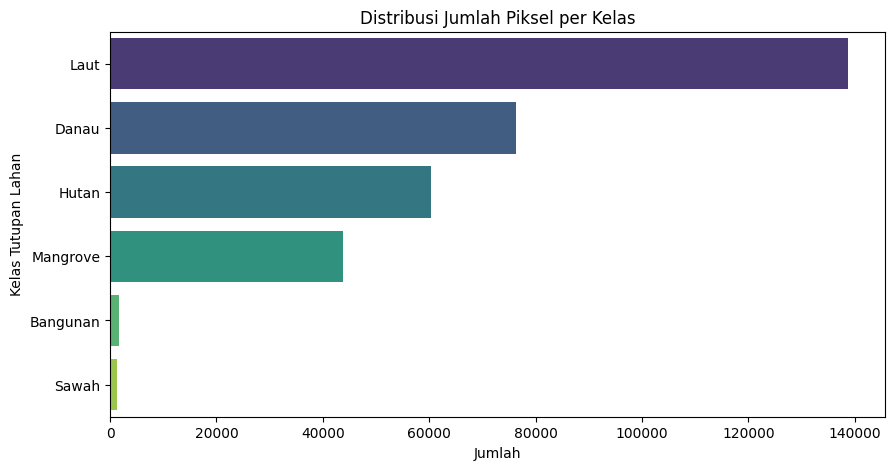

In [3]:
# Distribusi Kelas
plt.figure(figsize=(10, 5))
sns.countplot(y='label_teks', data=df, palette='viridis', order=df['label_teks'].value_counts().index)
plt.title('Distribusi Jumlah Piksel per Kelas')
plt.xlabel('Jumlah')
plt.ylabel('Kelas Tutupan Lahan')
plt.show()


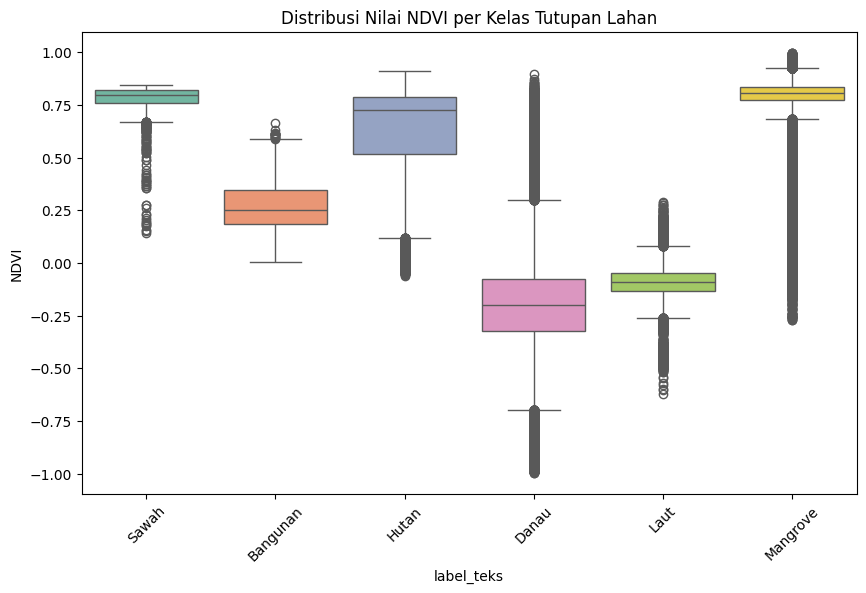

In [4]:
# Boxplot NDVI (Kerapatan Vegetasi) per Kelas
plt.figure(figsize=(10, 6))
sns.boxplot(x='label_teks', y='NDVI', data=df, palette='Set2')
plt.title('Distribusi Nilai NDVI per Kelas Tutupan Lahan')
plt.xticks(rotation=45)
plt.show()


---
## 4. Preprocessing Data
Membagi data menjadi variabel fitur (X) dan target (y), memisahkan data *training* dan *testing*, lalu melakukan standarisasi (*scaling*).


In [5]:
# 1. Menentukan Fitur (X) dan Target (y)
# Kita gunakan Band (B02, B03, B04, B08, B11) dan Indeks (NDVI, NDWI, MNDWI, NDBI)
fitur = ['B02', 'B03', 'B04', 'B08', 'B11', 'NDVI', 'NDWI', 'MNDWI', 'NDBI']

# Drop NaN jika ada
df_bersih = df.dropna(subset=fitur + ['label_teks']).copy()

X = df_bersih[fitur]
y = df_bersih['label_teks']

# 2. Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Standarisasi Fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Jumlah Data Latih: {X_train.shape[0]}")
print(f"Jumlah Data Uji: {X_test.shape[0]}")


Jumlah Data Latih: 257716
Jumlah Data Uji: 64430


---
## 5. Pemodelan (Modeling & Evaluasi)


### K-Nearest Neighbors (KNN)


=== HASIL EVALUASI K-NEAREST NEIGHBORS (KNN) ===
Akurasi : 98.18%

Classification Report:
               precision    recall  f1-score   support

    Bangunan       0.87      0.82      0.85       353
       Danau       0.98      0.96      0.97     15269
       Hutan       0.96      0.98      0.97     12058
        Laut       0.99      1.00      1.00     27746
    Mangrove       0.98      0.98      0.98      8753
       Sawah       0.92      0.89      0.90       251

    accuracy                           0.98     64430
   macro avg       0.95      0.94      0.94     64430
weighted avg       0.98      0.98      0.98     64430



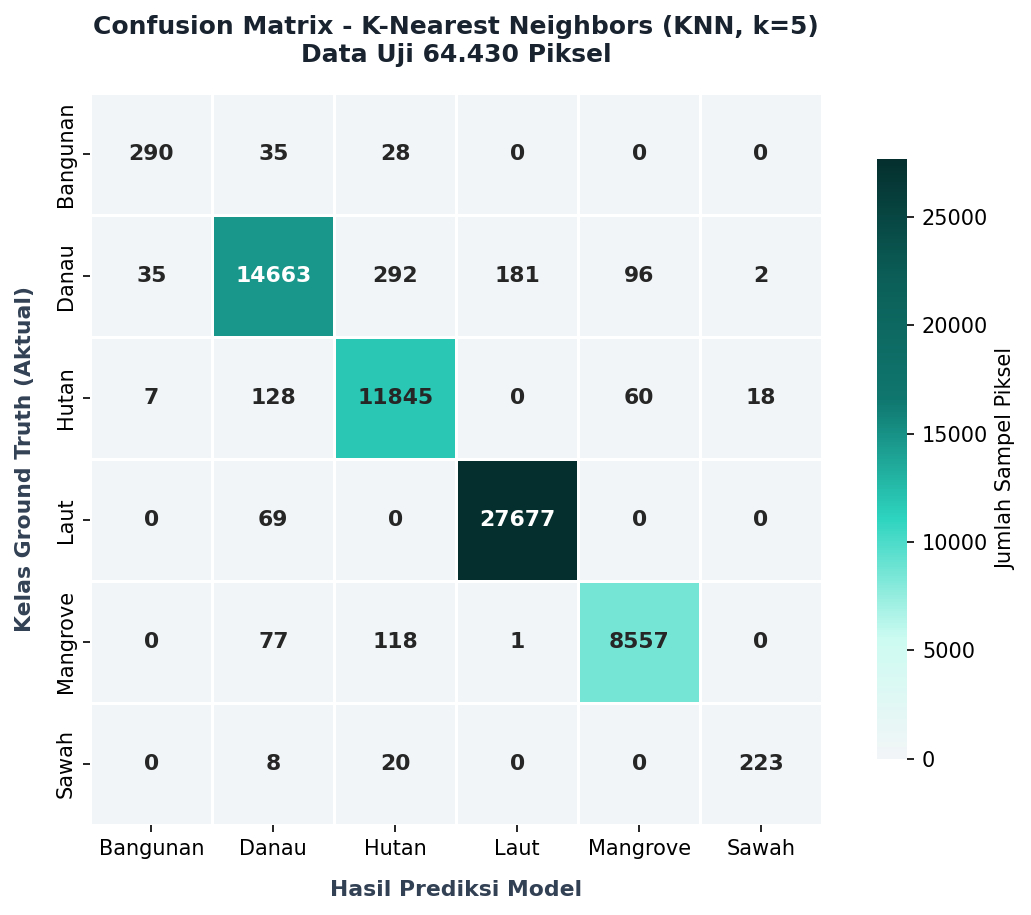

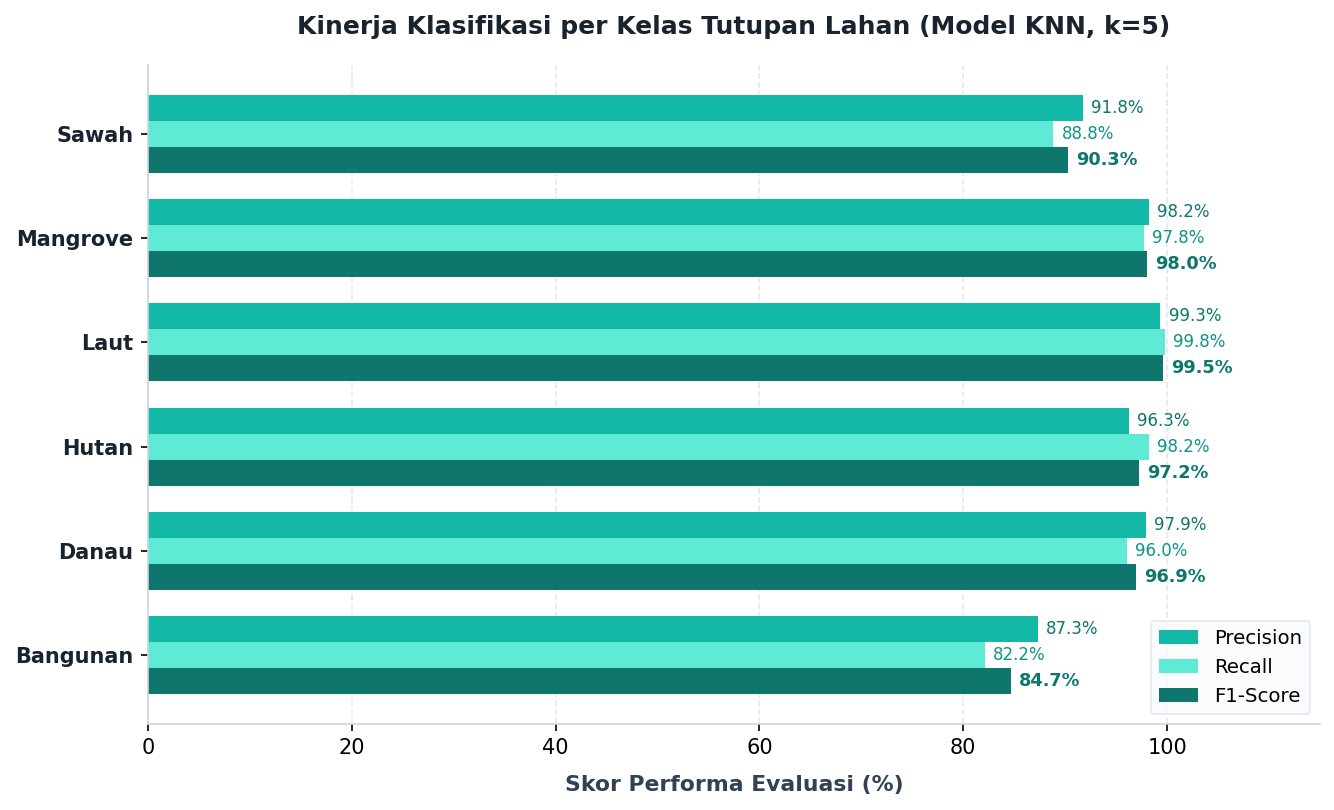

In [6]:
# Inisialisasi dan Pelatihan Model (KNN k=5)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

# Prediksi pada data testing
y_pred_knn = knn_model.predict(X_test_scaled)

# Evaluasi Teks
print("=== HASIL EVALUASI K-NEAREST NEIGHBORS (KNN) ===")
print(f"Akurasi : {accuracy_score(y_test, y_pred_knn)*100:.2f}%\n")
print("Classification Report:\n", classification_report(y_test, y_pred_knn))

# ==============================================================================
# VISUALISASI EVALUASI DENGAN PALET TEMA TEAL (SELARAS STREAMLIT DASHBOARD)
# ink: #18232F, teal: #0F766E, mint: #2DD4BF, paper: #F2F5F7
# ==============================================================================
import matplotlib.colors as mcolors

labels = sorted(y_test.unique())
cmap_teal = mcolors.LinearSegmentedColormap.from_list(
    "psd_teal_theme",
    ["#F2F5F7", "#CCFBF1", "#2DD4BF", "#0F766E", "#0B5F58", "#042F2E"]
)

# 1. Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred_knn, labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)

plt.figure(figsize=(8, 6.2), dpi=150)
sns.heatmap(
    cm_df,
    annot=True,
    fmt='d',
    cmap=cmap_teal,
    cbar=True,
    linewidths=1.2,
    linecolor="#FFFFFF",
    square=True,
    annot_kws={"size": 10.5, "weight": "bold"},
    cbar_kws={"shrink": 0.82, "label": "Jumlah Sampel Piksel"}
)
plt.title("Confusion Matrix - K-Nearest Neighbors (KNN, k=5)\nData Uji 64.430 Piksel", 
          fontsize=12, fontweight="bold", color="#18232F", pad=15)
plt.xlabel("Hasil Prediksi Model", fontsize=10.5, fontweight="600", color="#334155", labelpad=10)
plt.ylabel("Kelas Ground Truth (Aktual)", fontsize=10.5, fontweight="600", color="#334155", labelpad=10)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

# 2. Plot Kinerja Klasifikasi per Kelas (Precision, Recall, F1-Score)
report_dict = classification_report(y_test, y_pred_knn, labels=labels, output_dict=True)
df_metrics = pd.DataFrame([
    {
        "Kelas": lbl,
        "Precision": report_dict[lbl]["precision"] * 100,
        "Recall": report_dict[lbl]["recall"] * 100,
        "F1-Score": report_dict[lbl]["f1-score"] * 100
    }
    for lbl in labels
])

plt.figure(figsize=(9, 5.5), dpi=150)
y_indices = np.arange(len(labels))
bar_height = 0.25

plt.barh(y_indices + bar_height, df_metrics["Precision"], height=bar_height, label="Precision", color="#14B8A6")
plt.barh(y_indices, df_metrics["Recall"], height=bar_height, label="Recall", color="#5EEAD4")
plt.barh(y_indices - bar_height, df_metrics["F1-Score"], height=bar_height, label="F1-Score", color="#0F766E")

for i, row in df_metrics.iterrows():
    plt.text(row["F1-Score"] + 0.8, i - bar_height, f"{row['F1-Score']:.1f}%", 
             va="center", ha="left", fontsize=8.5, fontweight="bold", color="#0F766E")
    plt.text(row["Recall"] + 0.8, i, f"{row['Recall']:.1f}%", 
             va="center", ha="left", fontsize=8, color="#0D9488")
    plt.text(row["Precision"] + 0.8, i + bar_height, f"{row['Precision']:.1f}%", 
             va="center", ha="left", fontsize=8, color="#0F766E")

plt.yticks(y_indices, labels, fontsize=10, fontweight="600", color="#18232F")
plt.xlabel("Skor Performa Evaluasi (%)", fontsize=10.5, fontweight="600", color="#334155", labelpad=8)
plt.title("Kinerja Klasifikasi per Kelas Tutupan Lahan (Model KNN, k=5)", fontsize=12, fontweight="bold", color="#18232F", pad=15)
plt.xlim(0, 115)
plt.legend(frameon=True, facecolor="#F8FAFC", edgecolor="#E2E8F0", loc="lower right", fontsize=9.5)
plt.grid(axis="x", linestyle="--", alpha=0.5, color="#CBD5E1")
plt.gca().set_axisbelow(True)
for spine in ["top", "right"]:
    plt.gca().spines[spine].set_visible(False)
plt.gca().spines["left"].set_color("#CBD5E1")
plt.gca().spines["bottom"].set_color("#CBD5E1")
plt.tight_layout()
plt.savefig("kinerja_kelas.png", dpi=180, bbox_inches="tight")
plt.show()

---
## 6. Visualisasi Peta Hasil Klasifikasi / Digitasi
Memetakan seluruh titik hasil digitasi ke dalam peta **Folium** menggunakan pendekatan *Convex Hull* agar peta berjalan dengan ringan dan keseluruhan area terlihat sebagai satu kesatuan poligon.


In [8]:
# ==============================================================================
# 1. EVALUASI HASIL PREDIKSI DATA TESTING KE LEVEL POLIGON
# ==============================================================================
df_test = df_bersih.loc[X_test.index].copy()
df_test['prediksi_knn'] = y_pred_knn
df_test['benar'] = (df_test['label_teks'] == df_test['prediksi_knn'])

# Agregasi ke tingkat poligon berdasarkan mayoritas prediksi piksel
eval_poligon = df_test.groupby('poligon_id').agg(
    kelas_asli=('label_teks', 'first'),
    kelas_prediksi=('prediksi_knn', lambda s: s.mode()[0] if not s.empty else '-'),
    n_uji=('benar', 'count'),
    n_benar=('benar', 'sum'),
    akurasi_poly=('benar', 'mean')
).reset_index()

eval_poligon['status'] = np.where(
    eval_poligon['kelas_asli'] == eval_poligon['kelas_prediksi'], 'Benar', 'Salah'
)

poligon_salah = eval_poligon[eval_poligon['status'] == 'Salah'].copy()
print("Evaluasi Poligon Data Testing:")
print(f"- Total Poligon Uji : {len(eval_poligon)}")
print(f"- Poligon Benar     : {len(eval_poligon) - len(poligon_salah)}")
print(f"- Salah Klasifikasi : {len(poligon_salah)}\n")

if len(poligon_salah) > 0:
    tabel_salah = poligon_salah[['poligon_id', 'kelas_asli', 'kelas_prediksi', 'n_uji', 'n_benar', 'akurasi_poly']].copy()
    tabel_salah.columns = ['ID Poligon', 'Kelas Aktual', 'Prediksi Model', 'Total Piksel Uji', 'Piksel Benar', 'Akurasi']
    tabel_salah['Akurasi'] = tabel_salah['Akurasi'].apply(lambda x: f"{x*100:.1f}%")
    display(tabel_salah)

# ==============================================================================
# 2. REKONSTRUKSI POLIGON & PEMETAAN FOLIUM
# ==============================================================================
gdf = gpd.GeoDataFrame(
    df, geometry=gpd.points_from_xy(df.lon, df.lat), crs="EPSG:4326"
)

# Dissolve dan rekonstruksi geometri convex hull
polygons = gdf.dissolve(by='poligon_id', aggfunc='first').reset_index()
polygons['geometry'] = polygons['geometry'].convex_hull
polygons = polygons[~polygons['geometry'].is_empty]

# Gabungkan dengan hasil evaluasi testing
polygons = polygons.merge(eval_poligon, on='poligon_id', how='left')

# Inisialisasi Peta
map_center = [df['lat'].mean(), df['lon'].mean()]
m = folium.Map(
    location=map_center, 
    zoom_start=10, 
    tiles=None
)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles &copy; Esri",
    name="Esri World Imagery",
    overlay=False,
    control=True
).add_to(m)

folium.TileLayer(
    tiles="OpenStreetMap",
    name="OpenStreetMap",
    overlay=False,
    control=True
).add_to(m)

# Custom CSS: Tooltip modern tanpa outline/border, soft shadow
css_tooltip = """
<style>
.leaflet-tooltip {
    background: rgba(15, 23, 42, 0.94) !important;
    backdrop-filter: blur(8px) !important;
    color: #F8FAFC !important;
    border: none !important;
    outline: none !important;
    border-radius: 8px !important;
    padding: 10px 14px !important;
    box-shadow: 0 12px 28px -4px rgba(0, 0, 0, 0.35) !important;
    font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif !important;
    font-size: 12px !important;
    line-height: 1.5 !important;
}
.leaflet-tooltip-top:before,
.leaflet-tooltip-bottom:before,
.leaflet-tooltip-left:before,
.leaflet-tooltip-right:before {
    display: none !important;
}
</style>
"""
m.get_root().header.add_child(folium.Element(css_tooltip))

# Basemap telah ditambahkan pada inisialisasi peta

# Palet warna kurasi GIS
colors = {
    'Sawah': '#EAB308',
    'Bangunan': '#EF4444',
    'Mangrove': '#A855F7',
    'Lahan Hijau': '#15803D',
    'Hutan': '#15803D',
    'Perairan Terbuka (Laut)': '#1D4ED8',
    'Laut': '#1D4ED8',
    'Danau': '#06B6D4'
}

# 1. Layer Poligon Dasar per Kelas Tutupan Lahan
for label in polygons['label_teks'].unique():
    label_str = str(label)
    fg_kelas = folium.FeatureGroup(name=f"Kelas: {label_str}")
    sub_poly = polygons[polygons['label_teks'] == label_str]
    color = colors.get(label_str, '#475569')
    
    for idx, row in sub_poly.iterrows():
        tip_konten = f"""
        <div style="min-width: 140px;">
            <div style="font-weight: 700; font-size: 13px; color: #FFFFFF; margin-bottom: 2px;">{row['poligon_id']}</div>
            <div style="color: #94A3B8; font-size: 11px;">Kelas: <span style="color:#F1F5F9; font-weight:600;">{label_str}</span></div>
        </div>
        """
        try:
            folium.GeoJson(
                data=row['geometry'].__geo_interface__,
                style_function=lambda x, c=color: {
                    'fillColor': c,
                    'color': c,
                    'weight': 1,
                    'fillOpacity': 0.6
                },
                highlight_function=lambda x: {
                    'weight': 2.5,
                    'fillOpacity': 0.8
                },
                tooltip=folium.Tooltip(tip_konten, sticky=True)
            ).add_to(fg_kelas)
        except Exception:
            pass
    m.add_child(fg_kelas)

# 2. Layer Khusus: Salah Klasifikasi (Tanda seru muncul saat layer dicentang, hint muncul saat tanda seru dihover)
fg_salah = folium.FeatureGroup(name=f"Salah Klasifikasi ({len(poligon_salah)} Poligon)", show=True)
for idx, row in polygons[polygons['status'] == 'Salah'].iterrows():
    # Outline poligon salah klasifikasi
    try:
        folium.GeoJson(
            data=row['geometry'].__geo_interface__,
            style_function=lambda x: {
                'color': '#E11D48',
                'weight': 2.5,
                'dashArray': '4, 4',
                'fillColor': '#E11D48',
                'fillOpacity': 0.15
            },
            highlight_function=lambda x: {
                'weight': 3.5,
                'color': '#BE123C',
                'fillOpacity': 0.35
            }
        ).add_to(fg_salah)
    except Exception:
        pass
    
    # Titik tengah centroid poligon
    pt = row['geometry'].representative_point()
    
    # Desain badge tanda seru estetik & modern
    icon_tanda_seru = """
    <div style="width: 22px; height: 22px; background: #E11D48; border-radius: 50%;
                display: flex; align-items: center; justify-content: center;
                color: #FFFFFF; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;
                font-size: 13px; font-weight: 800; box-shadow: 0 4px 10px rgba(225, 29, 72, 0.45);
                cursor: pointer; border: 2px solid #FFFFFF;">
        !
    </div>
    """
    
    # Isi hint informasi: Kelas Aktual & Hasil Klasifikasi (tanpa outline)
    tip_salah = f"""
    <div style="min-width: 175px;">
        <div style="font-weight: 700; font-size: 13px; color: #FFFFFF; margin-bottom: 6px; letter-spacing: 0.2px;">
            {row['poligon_id']}
        </div>
        <div style="display: flex; justify-content: space-between; align-items: center; margin-bottom: 4px;">
            <span style="color: #94A3B8; font-size: 11px;">Kelas Aktual</span>
            <span style="background: rgba(16, 185, 129, 0.2); color: #34D399; padding: 1px 7px; border-radius: 4px; font-weight: 600; font-size: 11px;">
                {row['kelas_asli']}
            </span>
        </div>
        <div style="display: flex; justify-content: space-between; align-items: center; margin-bottom: 6px;">
            <span style="color: #94A3B8; font-size: 11px;">Hasil Klasifikasi</span>
            <span style="background: rgba(244, 63, 94, 0.2); color: #FB7185; padding: 1px 7px; border-radius: 4px; font-weight: 600; font-size: 11px;">
                {row['kelas_prediksi']}
            </span>
        </div>
        <div style="border-top: 1px solid rgba(255, 255, 255, 0.1); padding-top: 4px; font-size: 11px; color: #CBD5E1; display: flex; justify-content: space-between;">
            <span>Akurasi Piksel Uji</span>
            <span style="font-weight: 600;">{int(row['n_benar'])}/{int(row['n_uji'])} ({row['akurasi_poly']*100:.0f}%)</span>
        </div>
    </div>
    """
    
    # Pasang tanda seru dengan tooltip yang aktif saat dihover
    folium.Marker(
        location=[pt.y, pt.x],
        icon=folium.DivIcon(html=icon_tanda_seru, icon_size=(22, 22), icon_anchor=(11, 11)),
        tooltip=folium.Tooltip(tip_salah, sticky=False)
    ).add_to(fg_salah)

m.add_child(fg_salah)

# Tambahkan Legenda Interaktif Mengambang (Pojok Kiri Bawah)
legenda_html_1 = '''
<div style="
    position: fixed; 
    bottom: 25px; 
    left: 20px; 
    z-index: 9999; 
    background: rgba(255, 255, 255, 0.94); 
    backdrop-filter: blur(8px); 
    border: 1px solid rgba(203, 213, 225, 0.85); 
    border-radius: 10px; 
    padding: 12px 14px; 
    font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; 
    box-shadow: 0 8px 24px rgba(15, 23, 42, 0.15); 
    min-width: 175px;
">
    <div style="display: flex; align-items: center; justify-content: space-between; border-bottom: 1px solid #E2E8F0; padding-bottom: 6px; margin-bottom: 8px;">
        <span style="font-weight: 700; font-size: 12.5px; color: #0F766E; letter-spacing: -0.01em;">Legenda Tutupan Lahan</span>
        <span style="font-size: 10px; font-weight: 600; color: #64748B; background: #F1F5F9; padding: 2px 6px; border-radius: 4px; border: 1px solid #E2E8F0;">Vektor Poligon</span>
    </div>
    <div style="display: flex; align-items: center; gap: 8px; margin-bottom: 5px;"><span style="width: 13px; height: 13px; border-radius: 3px; background: #FFD92F; display: inline-block;"></span><span style="font-weight: 600; font-size: 11.5px; color: #334155;">Sawah</span></div>
    <div style="display: flex; align-items: center; gap: 8px; margin-bottom: 5px;"><span style="width: 13px; height: 13px; border-radius: 3px; background: #E41A1C; display: inline-block;"></span><span style="font-weight: 600; font-size: 11.5px; color: #334155;">Bangunan</span></div>
    <div style="display: flex; align-items: center; gap: 8px; margin-bottom: 5px;"><span style="width: 13px; height: 13px; border-radius: 3px; background: #2E7D32; display: inline-block;"></span><span style="font-weight: 600; font-size: 11.5px; color: #334155;">Hutan</span></div>
    <div style="display: flex; align-items: center; gap: 8px; margin-bottom: 5px;"><span style="width: 13px; height: 13px; border-radius: 3px; background: #4FC3F7; display: inline-block;"></span><span style="font-weight: 600; font-size: 11.5px; color: #334155;">Danau</span></div>
    <div style="display: flex; align-items: center; gap: 8px; margin-bottom: 5px;"><span style="width: 13px; height: 13px; border-radius: 3px; background: #0D47A1; display: inline-block;"></span><span style="font-weight: 600; font-size: 11.5px; color: #334155;">Laut</span></div>
    <div style="display: flex; align-items: center; gap: 8px; margin-bottom: 5px;"><span style="width: 13px; height: 13px; border-radius: 3px; background: #8E44AD; display: inline-block;"></span><span style="font-weight: 600; font-size: 11.5px; color: #334155;">Mangrove</span></div>
    <div style="border-top: 1px solid #E2E8F0; margin-top: 8px; padding-top: 6px;">
        <div style="display: flex; align-items: center; gap: 8px;">
            <span style="width: 15px; height: 15px; border-radius: 50%; background: #E11D48; color: #FFFFFF; display: inline-flex; align-items: center; justify-content: center; font-size: 10px; font-weight: 800; line-height: 1;">!</span>
            <span style="font-weight: 600; color: #E11D48; font-size: 11px;">Salah Klasifikasi (9)</span>
        </div>
    </div>
</div>
'''
m.get_root().html.add_child(folium.Element(legenda_html_1))

folium.LayerControl(collapsed=False).add_to(m)
m.save("peta_klasifikasi_rf.html")

# Tampilkan Peta
m

Evaluasi Poligon Data Testing:
- Total Poligon Uji : 268
- Poligon Benar     : 259
- Salah Klasifikasi : 9



,ID Poligon,Kelas Aktual,Prediksi Model,Total Piksel Uji,Piksel Benar,Akurasi
3,Bangunan_0003,Bangunan,Danau,2,0,0.0%
6,Bangunan_0007,Bangunan,Hutan,5,2,40.0%
24,Bangunan_0027,Bangunan,Hutan,3,1,33.3%
85,Danau_0041,Danau,Laut,9,4,44.4%
224,Sawah_0004,Sawah,Hutan,5,1,20.0%
231,Sawah_0013,Sawah,Hutan,7,3,42.9%
252,Sawah_0035,Sawah,Danau,2,1,50.0%
253,Sawah_0036,Sawah,Hutan,2,1,50.0%
264,Sawah_0047,Sawah,Hutan,3,1,33.3%


In [1]:
import os
import rasterio
import numpy as np
import folium
import openeo

# Fungsi pembantu: konversi kode warna hex (#RRGGBB) ke (R, G, B)
def hex_to_rgb(hex_code):
    hex_code = hex_code.lstrip('#')
    return tuple(int(hex_code[i:i+2], 16) for i in (0, 2, 4))

# Tentukan path raster wilayah utuh
FILE_RASTER = 'jatim_250m.tif' 

# 1. UNDUH DATA VIA OPENEO (MENGGUNAKAN BATCH JOB KARENA AREA BESAR)
if not os.path.exists(FILE_RASTER):
    print("Mengunduh komposit Jawa Timur via openEO Batch Job (Resolusi ~250m)...")
    try:
        # Hubungkan ke CDSE openEO
        connection = openeo.connect("https://openeo.dataspace.copernicus.eu").authenticate_oidc()
        
        # Bounding Box Kasar untuk wilayah Jawa Timur
        bbox_jatim = {
            "west": 110.89, "south": -8.84,
            "east": 114.63, "north": -6.65
        }
        
        cube = connection.load_collection(
            "SENTINEL2_L2A",
            spatial_extent=bbox_jatim,
            temporal_extent=["2026-08-01", "2026-08-31"],
            bands=['B02', 'B03', 'B04', 'B08', 'B11'],
            max_cloud_cover=30
        )
        
        # Agregasi waktu (Median) untuk membersihkan sisa awan
        cube = cube.median_time()
        
        # Turunkan resolusi spasial ke 0.0025 derajat (~250 meter)
        cube = cube.resample_spatial(resolution=0.0025, projection=4326)
        cube = cube.save_result(format="GTiff")
        
        # Jalankan via Batch Job
        print("Membuat batch job di openEO server...")
        job = cube.create_job(title="Jatim_Composite_250m")
        job.start_and_wait()
        
        # Unduh asset hasil job ke folder lokal
        results = job.get_results()
        results.download_file(FILE_RASTER)
        print("Unduhan batch job selesai dan tersimpan di:", FILE_RASTER)

    except Exception as e:
        print(f"Gagal memproses data openEO: {e}")

# 2. BACA RASTER DAN LAKUKAN PREDIKSI
if os.path.exists(FILE_RASTER):
    with rasterio.open(FILE_RASTER) as src:
        b2 = src.read(1).astype(float)
        b3 = src.read(2).astype(float)
        b4 = src.read(3).astype(float)
        b8 = src.read(4).astype(float)
        b11 = src.read(5).astype(float)
        
        bounds = src.bounds
        img_bounds = [[bounds.bottom, bounds.left], [bounds.top, bounds.right]]
        center_lat = (bounds.bottom + bounds.top) / 2
        center_lon = (bounds.left + bounds.right) / 2

    # Menghitung ulang Indeks Spektral
    e = 1e-9
    ndvi = (b8 - b4) / (b8 + b4 + e)
    ndwi = (b3 - b8) / (b3 + b8 + e)
    mndwi = (b3 - b11) / (b3 + b11 + e)
    ndbi = (b11 - b8) / (b11 + b8 + e)
    
    height, width = b2.shape
    
    # Ratakan (flatten) array 2D menjadi 1D
    features_stack = np.column_stack((
        b2.flatten(), b3.flatten(), b4.flatten(), b8.flatten(), b11.flatten(),
        ndvi.flatten(), ndwi.flatten(), mndwi.flatten(), ndbi.flatten()
    ))
    
    # Deteksi piksel valid
    valid_mask = (b2.flatten() > 0)
    
    # Scaling fitur
    features_scaled = scaler.transform(features_stack)
    
    # Prediksi
    pred_1d = knn_model.predict(features_scaled)
    pred_2d = pred_1d.reshape((height, width))
    valid_2d = valid_mask.reshape((height, width))
    
    # 3. PLOTTING KE PETA FOLIUM
    m_full = folium.Map(
        location=[center_lat, center_lon], 
        zoom_start=8, 
        tiles=None
    )
    
    # Basemap Esri Satellite (Stabil & Bebas Error HTTP 400 Google)
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
        attr="Tiles &copy; Esri &mdash; Source: Esri, Maxar, Earthstar Geographics",
        name="Esri Satellite",
        max_zoom=19,
        overlay=False,
        control=True
    ).add_to(m_full)
    
    # Basemap Peta Jalan OpenStreetMap
    folium.TileLayer(
        tiles="OpenStreetMap",
        name="OpenStreetMap",
        overlay=False,
        control=True
    ).add_to(m_full)
    
    # Buat Image Overlay untuk tiap kelas (dengan opasitas seimbang agar satelit terlihat)
    for label_str, hex_color in colors.items():
        rgba_img = np.zeros((height, width, 4), dtype=np.uint8)
        mask = (pred_2d == label_str) & valid_2d
        
        if np.any(mask):
            r, g, b = hex_to_rgb(hex_color)
            rgba_img[mask, 0] = r
            rgba_img[mask, 1] = g
            rgba_img[mask, 2] = b
            rgba_img[mask, 3] = 160  # Opacity 160/255 agar citra satelit terlihat tembus pandang
            
            folium.raster_layers.ImageOverlay(
                image=rgba_img,
                bounds=img_bounds,
                opacity=0.8,
                name=f"Sebaran {label_str}",
                show=True
            ).add_to(m_full)
    
        # Tambahkan Legenda Interaktif Mengambang (Pojok Kiri Bawah)
    legenda_html_2 = '''
    <div style="
        position: fixed; 
        bottom: 25px; 
        left: 20px; 
        z-index: 9999; 
        background: rgba(255, 255, 255, 0.94); 
        backdrop-filter: blur(8px); 
        border: 1px solid rgba(203, 213, 225, 0.85); 
        border-radius: 10px; 
        padding: 12px 14px; 
        font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; 
        box-shadow: 0 8px 24px rgba(15, 23, 42, 0.15); 
        min-width: 175px;
    ">
        <div style="display: flex; align-items: center; justify-content: space-between; border-bottom: 1px solid #E2E8F0; padding-bottom: 6px; margin-bottom: 8px;">
            <span style="font-weight: 700; font-size: 12px; color: #0F766E;">Legenda Tutupan Lahan</span>
            <span style="font-size: 10px; font-weight: 600; color: #64748B; background: #F1F5F9; padding: 2px 6px; border-radius: 4px;">Raster 250m</span>
        </div>
        <div style="display: flex; align-items: center; gap: 8px; margin-bottom: 5px;"><span style="width: 13px; height: 13px; border-radius: 3px; background: #FFD92F; display: inline-block;"></span><span style="font-weight: 600; font-size: 11.5px; color: #334155;">Sawah</span></div>
        <div style="display: flex; align-items: center; gap: 8px; margin-bottom: 5px;"><span style="width: 13px; height: 13px; border-radius: 3px; background: #E41A1C; display: inline-block;"></span><span style="font-weight: 600; font-size: 11.5px; color: #334155;">Bangunan</span></div>
        <div style="display: flex; align-items: center; gap: 8px; margin-bottom: 5px;"><span style="width: 13px; height: 13px; border-radius: 3px; background: #2E7D32; display: inline-block;"></span><span style="font-weight: 600; font-size: 11.5px; color: #334155;">Hutan</span></div>
        <div style="display: flex; align-items: center; gap: 8px; margin-bottom: 5px;"><span style="width: 13px; height: 13px; border-radius: 3px; background: #4FC3F7; display: inline-block;"></span><span style="font-weight: 600; font-size: 11.5px; color: #334155;">Danau</span></div>
        <div style="display: flex; align-items: center; gap: 8px; margin-bottom: 5px;"><span style="width: 13px; height: 13px; border-radius: 3px; background: #0D47A1; display: inline-block;"></span><span style="font-weight: 600; font-size: 11.5px; color: #334155;">Laut</span></div>
        <div style="display: flex; align-items: center; gap: 8px; margin-bottom: 5px;"><span style="width: 13px; height: 13px; border-radius: 3px; background: #8E44AD; display: inline-block;"></span><span style="font-weight: 600; font-size: 11.5px; color: #334155;">Mangrove</span></div>
        <div style="border-top: 1px solid #E2E8F0; margin-top: 6px; padding-top: 5px; font-size: 10px; color: #64748B;">Opasitas: 65%</div>
    </div>
    '''
    m_full.get_root().html.add_child(folium.Element(legenda_html_2))

    folium.LayerControl(collapsed=False).add_to(m_full)
    m_full.save("hasil_klasifikasi_random_forest.html")
    display(m_full)
else:
    print("Tidak dapat menampilkan peta karena file raster tidak tersedia.")

ModuleNotFoundError: No module named 'rasterio'